In [1]:
from data_analysis_utils import *

# No TDD, no refinement
DEFAULT_PREFIX = "default"
DEFAULT_SUBFOLDERS = ["default_0_54", "default_55_109", "default_110_163"]

# No TDD, refinement
REF_PREFIX = ""
REF_SUBFOLDERS = []

# TDD, no refinement
TDD_PREFIX = ""
TDD_SUBFOLDERS = []

# TDD, refinement
TDD_REF_PREFIX = "tdd_refine"
TDD_REF_SUBFOLDERS = ["my_experiment"]

AGENT_SCENARIOS = {
    "default": (DEFAULT_PREFIX, DEFAULT_SUBFOLDERS),
    "refine": (REF_PREFIX, REF_SUBFOLDERS),
    "tdd": (TDD_PREFIX, TDD_SUBFOLDERS), 
    "tdd_refine": (TDD_REF_PREFIX, TDD_REF_SUBFOLDERS),
}


In [2]:
import sys
sys.path.insert(0, '..')

from recheck_data import recheck_data

# There is probably a much better way to do this, but i am hardcoding it for now
instance_numbers = {
  "default_0_54": {
    "start": 0,
    "end": 54,
  },
  "default_55_109": {
    "start": 55,
    "end": 109,
  },
  "default_110_163": {
    "start": 110,
    "end": 163,
  },
  "my_experiment": {
    "start": 0,
    "end": 50,
  }
}

for scenario, (prefix, subfolders) in AGENT_SCENARIOS.items():
  for subfolder in subfolders:
    recheck_data(prefix, subfolder, instance_numbers.get(subfolder)["start"], instance_numbers.get(subfolder)["end"])

c:\Users\rapha\Desktop\MSc Computer Science\CS4570 Machine Learning for Software Engineering\tdlite\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df_summaries = aggregate_json(agent_scenarios=AGENT_SCENARIOS)

#df_default = aggregate_csv(prefix=DEFAULT_PREFIX, subfolders=DEFAULT_SUBFOLDERS)
df_instances = aggregate_csv_scenarios(AGENT_SCENARIOS)
df_instances = add_unrolled_token_cost_column(df_instances)

In [4]:
df_summaries.head()

,total,passed,pass_rate,avg_iters,tokens_input,tokens_output,avg_line_coverage,avg_branch_coverage,avg_mutation_score,tokens_a11_input,tokens_a11_output,tokens_a12_input,tokens_a12_output,tokens_a2_input,tokens_a2_output,tokens_a3_input,tokens_a3_output,tokens_a4_input,tokens_a4_output
scenario,,,,,,,,,,,,,,,,,,,
default,164.0,133.0,0.810976,1.00000,3184384.0,1429468.0,0.000000,0.0,-1.0,0.0,0.0,0.0,0.0,2197312.0,1099977.0,987072.0,329491.0,0.0,0.0
tdd_refine,51.0,45.0,0.882353,1.54902,12781773.0,2008074.0,43.917647,0.0,-1.0,2080851.0,507654.0,3705813.0,893265.0,3568674.0,296922.0,83691.0,26265.0,3342744.0,283968.0
refine,NaN,NaN,0.000000,-1.00000,NaN,NaN,-1.000000,-1.0,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tdd,NaN,NaN,0.000000,-1.00000,NaN,NaN,-1.000000,-1.0,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df_instances.head()

,scenario,batch,passed_hidden_tests,pipeline_tests_passed,pipeline_iterations,coverage_tests_run,coverage_tests_failed,coverage_tests_errors,coverage_tests_passed,coverage_test_file,...,a12_output_tokens,a2_input_tokens,a2_output_tokens,a3_input_tokens,a3_output_tokens,a4_input_tokens,a4_output_tokens,instance_id,token_cost_cumulative,token_cost_unrolled
0,default,default_0_54,True,False,1,0,0,0,False,NaN,...,0,230,72,0,0,0,0,1,302,302.0
1,default,default_0_54,True,False,1,0,0,0,False,NaN,...,0,451,199,0,0,0,0,2,650,348.0
2,default,default_0_54,True,False,1,0,0,0,False,NaN,...,0,642,212,229,26,0,0,3,1109,459.0
3,default,default_0_54,True,False,1,0,0,0,False,NaN,...,0,867,266,229,26,0,0,4,1388,279.0
4,default,default_0_54,True,False,1,0,0,0,False,NaN,...,0,1090,335,229,26,0,0,5,1680,292.0


In [6]:
# Generate tables for paper results

group_col = "scenario"

print("Pass rate:")
display(df_summaries)

print("Token cost:")
token_cost_summary = summarize_numeric_by_group(df_instances, group_col, "token_cost_unrolled")
display(token_cost_summary)

print("Number of iterations:")
iterations_summary = summarize_numeric_by_group(df_instances, group_col, "pipeline_iterations")
display(iterations_summary)

print("Test quality (line coverage, branch coverage, mutation score)")
linecov_summary = summarize_numeric_by_group(df_instances, group_col, "line_coverage_percent", drop_negative=True)
branchcov_summary = summarize_numeric_by_group(df_instances, group_col, "branch_coverage_percent", drop_negative=True)
mutation_summary = summarize_numeric_by_group(df_instances, group_col, "mutation_score", drop_negative=True)
display(linecov_summary)
display(branchcov_summary)
display(mutation_summary)

Pass rate:


,total,passed,pass_rate,avg_iters,tokens_input,tokens_output,avg_line_coverage,avg_branch_coverage,avg_mutation_score,tokens_a11_input,tokens_a11_output,tokens_a12_input,tokens_a12_output,tokens_a2_input,tokens_a2_output,tokens_a3_input,tokens_a3_output,tokens_a4_input,tokens_a4_output
scenario,,,,,,,,,,,,,,,,,,,
default,164.0,133.0,0.810976,1.00000,3184384.0,1429468.0,0.000000,0.0,-1.0,0.0,0.0,0.0,0.0,2197312.0,1099977.0,987072.0,329491.0,0.0,0.0
tdd_refine,51.0,45.0,0.882353,1.54902,12781773.0,2008074.0,43.917647,0.0,-1.0,2080851.0,507654.0,3705813.0,893265.0,3568674.0,296922.0,83691.0,26265.0,3342744.0,283968.0
refine,NaN,NaN,0.000000,-1.00000,NaN,NaN,-1.000000,-1.0,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tdd,NaN,NaN,0.000000,-1.00000,NaN,NaN,-1.000000,-1.0,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Token cost:


,count,mean,median,std,min,max
scenario,,,,,,
default,164,513.969512,323.0,1468.664547,187.0,18746.0
tdd_refine,51,5686.215686,3375.0,7440.474107,2288.0,50943.0


Number of iterations:


,count,mean,median,std,min,max
scenario,,,,,,
default,164,1.00000,1.0,0.000000,1,1
tdd_refine,51,1.54902,1.0,1.361084,1,8


Test quality (line coverage, branch coverage, mutation score)


,count,mean,median,std,min,max
scenario,,,,,,
default,164,0.000000,0.0,0.000000,0.0,0.0
tdd_refine,51,43.917647,50.0,29.286454,0.0,100.0


,count,mean,median,std,min,max
scenario,,,,,,
default,164,0.0,0.0,0.0,0.0,0.0
tdd_refine,51,0.0,0.0,0.0,0.0,0.0


,count,mean,median,std,min,max
scenario,,,,,,


In [7]:
print("We compare influence of TDD and pass rates with pair wise Fischer tests")
print("TDD influence on pass rate")
# display(compare_pass_rates(df_summaries, "default", "tdd"))
# display(compare_pass_rates(df_summaries, "refine", "tdd-refine"))

print("Refinement influence on pass rate")
# display(compare_pass_rates(df_summaries, "default", "refine"))
# display(compare_pass_rates(df_summaries, "tdd", "tdd_refine"))


We compare influence of TDD and pass rates with pair wise Fischer tests
TDD influence on pass rate
Refinement influence on pass rate


In [8]:
print("We compare influence of TDD and refinement on token cost with MannWhitney U tests")

print("TDD influence on token costs")
# display(compare_token_costs(df_instances, "default", "tdd"))
# display(compare_token_costs(df_instances, "refine", "tdd_refine"))

print("Refinement influence on token costs")
# display(compare_token_costs(df_instances, "default", "refine"))
# display(compare_token_costs(df_instances, "tdd", "tdd_refine"))

We compare influence of TDD and refinement on token cost with MannWhitney U tests
TDD influence on token costs
Refinement influence on token costs


In [9]:
print("We compare influence of test quality on pass rate")

df_test_quality = df_instances.copy()
df_test_quality["passed_partition"] = df_test_quality["scenario"] + "_" + df_test_quality["passed_hidden_tests"].astype(str)

print("Influence of test quality on pass rate for TDD with refinement:")
display(compare_quality_metric(df_test_quality, "tdd_refine_True", "tdd_refine_False", group_col="passed_partition", metric_col="line_coverage_percent", drop_negative=False))
display(compare_quality_metric(df_test_quality, "tdd_refine_True", "tdd_refine_False", group_col="passed_partition", metric_col="branch_coverage_percent", drop_negative=False))
display(compare_quality_metric(df_test_quality, "tdd_refine_True", "tdd_refine_False", group_col="passed_partition", metric_col="mutation_score", drop_negative=False))

print("Influence of test quality on pass rate for TDD w/o refinement")
# display(compare_quality_metric(df_test_quality, "tdd_True", "tdd_False", group_col="passed_partition", metric_col="line_coverage_percent", drop_negative=False))
# display(compare_quality_metric(df_test_quality, "tdd_True", "tdd_False", group_col="passed_partition", metric_col="branch_coverage_percent", drop_negative=False))
# display(compare_quality_metric(df_test_quality, "tdd_True", "tdd_False", group_col="passed_partition", metric_col="mutation_score", drop_negative=False))

We compare influence of test quality on pass rate
Influence of test quality on pass rate for TDD with refinement:


,passed_partition,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,tdd_refine_True,tdd_refine_False,line_coverage_percent,43.594222,46.343333,0.905977,False


,passed_partition,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,tdd_refine_True,tdd_refine_False,branch_coverage_percent,0.0,0.0,1.0,False


,passed_partition,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,tdd_refine_True,tdd_refine_False,mutation_score,-1.0,-1.0,1.0,False


Influence of test quality on pass rate for TDD w/o refinement


In [ ]:
print("We compare influence of test quality on token cost")

print("Influence of test quality on cost with TDD with refinement")
display(compare_metric_spearman_rho(df_test_quality, "tdd_refine", "line_coverage_percent", "token_cost_unrolled"))
display(compare_metric_spearman_rho(df_test_quality, "tdd_refine", "branch_coverage_percent", "token_cost_unrolled"))
display(compare_metric_spearman_rho(df_test_quality, "tdd_refine", "mutation_score", "token_cost_unrolled"))

print("Influence of test quality on cost with TDD w/o refinement")
# display(compare_metric_spearman_rho(df_test_quality, "tdd", "line_coverage_percent", "token_cost_unrolled"))
# display(compare_metric_spearman_rho(df_test_quality, "tdd", "branch_coverage_percent", "token_cost_unrolled"))
# display(compare_metric_spearman_rho(df_test_quality, "tdd", "mutation_score", "token_cost_unrolled"))

We compare influence of test quality on token cost
Influence of test quality on cost with TDD with refinement


,tdd_refine,left_metric,right_metric,left_mean,right_mean,spearmanr_stat,p_value,significant_0.05
0,tdd_refine,line_coverage_percent,token_cost_unrolled,43.917647,5686.215686,0.01787,0.900949,False


c:\Users\rapha\Desktop\MSc Computer Science\CS4570 Machine Learning for Software Engineering\tdlite\data_analysis\data_analysis_utils.py:420: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  stat, p_value = spearmanr(left, right)


,tdd_refine,left_metric,right_metric,left_mean,right_mean,spearmanr_stat,p_value,significant_0.05
0,tdd_refine,branch_coverage_percent,token_cost_unrolled,0.0,5686.215686,NaN,NaN,False


c:\Users\rapha\Desktop\MSc Computer Science\CS4570 Machine Learning for Software Engineering\tdlite\data_analysis\data_analysis_utils.py:420: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  stat, p_value = spearmanr(left, right)


,tdd_refine,left_metric,right_metric,left_mean,right_mean,spearmanr_stat,p_value,significant_0.05
0,tdd_refine,mutation_score,token_cost_unrolled,-1.0,5686.215686,NaN,NaN,False


,scenario,comparison_group,metric,left_rate,right_rate,n_left,n_right,successes_left,successes_right,p_value,significant_0.05
0,default,tdd_refine,passed,0.810976,0.882353,164.0,51.0,133.0,45.0,0.29205,False


,scenario,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,default,tdd_refine,token_cost_unrolled,513.969512,5686.215686,1.881929e-26,True


,scenario,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,default,tdd_refine,pipeline_iterations,1.0,1.54902,2.966132e-11,True


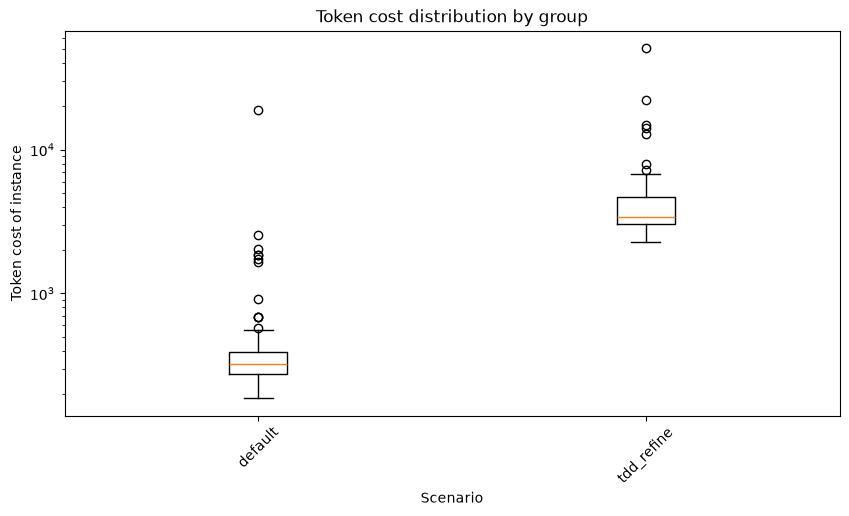

In [ ]:
# Analyze and compare probability distributions of metrics in different scenarios

ax = plot_token_cost_distribution(df_instances, group_col=group_col)
# axes = plot_metric_relationships(df_instances, group_col=group_col)

scenario_names = list(df_instances["scenario"].dropna().unique())
if len(scenario_names) >= 2:
    display(compare_pass_rates(df_summaries, scenario_names[0], scenario_names[1]))
    display(compare_token_costs(df_instances, scenario_names[0], scenario_names[1]))
    display(compare_quality_metric(df_instances, scenario_names[0], scenario_names[1], metric_col="pipeline_iterations"))
else:
    print("Only one scenario is present in AGENT_SCENARIOS. Add another scenario to run cross-scenario significance tests.")
